# RAG agéntico · self-correcting (LangGraph + MCP)

> El RAG lineal (notebook 04) recupera UNA vez y responde. Aquí montamos el patrón **agéntico**:
> un grafo que **planifica, recupera de varias fuentes, juzga si el contexto basta y, si no, vuelve
> a intentarlo** escalando a mejores fuentes. Y lo más importante: **vemos por dónde va el grafo**.

## El grafo (mapea el diagrama de las slides)

```
question -> [plan] -> [retrieve] -> [grade] --suficiente?--> [synthesize] -> answer
                ^                       |
                |_______ no (razones) __|   (loop de autocorrección)
```

- **plan** · planner & query rewriter: reescribe la consulta y detecta la librería.
- **retrieve** · fanout: el pase 1 busca en el **código local**; si no basta, escala a la
  **documentación viva vía MCP (context7)**.
- **grade** · sufficient-context agent: ¿los fragmentos bastan? Si no, da las razones y se reintenta.
- **synthesize** · compone la respuesta citando fuentes.

## Qué aprendemos

1. Por qué el RAG lineal se queda corto y cómo el loop self-correcting lo arregla.
2. LangGraph: `StateGraph`, nodos, `add_conditional_edges` (el ciclo) y cómo **visualizar el grafo**
   y **trazar la ruta** que sigue en cada ejecución.
3. Conectar una **fuente viva vía MCP** (context7 = documentación de librerías al día).

## Stack

`langgraph` · `langchain-openai` (gpt-5-mini) · `langchain-mcp-adapters` + **context7** · `chroma`.

## Hardware

Sin GPU · todo es API + un vector store pequeño. Corre en Colab tal cual.

In [1]:
!pip install -qU langgraph langchain-openai langchain-mcp-adapters langchain-chroma chromadb

## 1 · Claves y modelo

`OPENAI_API_KEY` para el LLM. `CONTEXT7_API_KEY` es **opcional** (sin ella context7 funciona con
límite de uso; con ella vas más holgado: https://context7.com/dashboard).

In [2]:
import os, getpass
os.environ["OPENAI_API_KEY"] = os.environ.get("OPENAI_API_KEY") or getpass.getpass("OPENAI_API_KEY: ")
CONTEXT7_API_KEY = getpass.getpass("CONTEXT7_API_KEY (enter para saltar): ") or None

from langchain_openai import ChatOpenAI, OpenAIEmbeddings
llm = ChatOpenAI(model="gpt-5-mini")          # planner / grader / synthesizer
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")
print("modelo:", llm.model_name)

modelo: gpt-5-mini


## 2 · Fuente local · corpus de CÓDIGO

Un vector store pequeño con snippets **genéricos** de Python. A propósito NO cubren bien preguntas
de APIs concretas y actuales: por eso el agente tendrá que escalar a la documentación viva.

In [3]:
from langchain_chroma import Chroma

CODE_SNIPPETS = [
    "import requests\nr = requests.get(url)\nprint(r.json())  # petición HTTP síncrona básica",
    "import json\ndata = json.loads(texto)  # parsear JSON a dict",
    "with open('f.txt') as f:\n    txt = f.read()  # leer un fichero",
    "import threading\nfor u in urls:\n    threading.Thread(target=descargar, args=(u,)).start()  # paralelismo con hilos",
    "try:\n    riesgoso()\nexcept ValueError as e:\n    print(e)  # capturar una excepción concreta",
    "import time\nfor i in range(3):\n    try: hacer(); break\n    except: time.sleep(2**i)  # retry casero",
]
code_db = Chroma.from_texts(CODE_SNIPPETS, embedding=embeddings, collection_name="codigo-local")
code_retriever = code_db.as_retriever(search_kwargs={"k": 3})
print("corpus de código local:", len(CODE_SNIPPETS), "snippets")

corpus de código local: 6 snippets


## 3 · Fuente viva vía MCP · context7

[context7](https://context7.com) es un servidor **MCP** que sirve documentación de librerías
**al día**. Lo conectamos con `langchain-mcp-adapters` y exponemos sus tools (`resolve-library-id`
y `query-docs`). Envolvemos la llamada en un helper defensivo: si el MCP no está disponible,
el lab sigue funcionando (solo pierde esa fuente).

Los servidores MCP evolucionan: context7 renombró `get-library-docs` a `query-docs` y ahora ambas tools
exigen un parámetro `query`. Por eso el helper localiza las tools por nombre y comprueba que la
respuesta no sea un error de validación antes de usarla como contexto.

In [4]:
from langchain_mcp_adapters.client import MultiServerMCPClient
import re

_cfg = {"context7": {"transport": "streamable_http", "url": "https://mcp.context7.com/mcp"}}
if CONTEXT7_API_KEY:
    _cfg["context7"]["headers"] = {"CONTEXT7_API_KEY": CONTEXT7_API_KEY}

mcp_client = MultiServerMCPClient(_cfg)
try:
    mcp_tools = await mcp_client.get_tools()
    print("tools de context7:", [t.name for t in mcp_tools])
except Exception as e:
    mcp_tools = []
    print("context7 no conectado:", str(e)[:120])

_resolve = next((t for t in mcp_tools if "resolve" in t.name), None)
_docs    = next((t for t in mcp_tools if "docs" in t.name), None)

def _texto(out):
    """Las tools MCP devuelven una lista de bloques de contenido: nos quedamos con el texto."""
    if isinstance(out, list):
        return "\n".join(b.get("text", "") if isinstance(b, dict) else str(b) for b in out)
    return str(out)

async def fetch_context7(library, topic, max_chars=4000):
    """Resuelve la librería y trae su documentación viva. Devuelve '' si falla."""
    if not (_resolve and _docs):
        return ""
    try:
        rid = _texto(await _resolve.ainvoke({"libraryName": library, "query": topic}))
        m = re.search(r"library ID:\s*(/[\w.\-]+/[\w.\-]+)", rid)
        if not m:
            return ""
        out = _texto(await _docs.ainvoke({"libraryId": m.group(1), "query": topic}))
        if out.startswith("MCP error") or "validation error" in out.lower():
            print("   context7 devolvió un error:", out[:80]); return ""
        return out[:max_chars]
    except Exception as e:
        print("   context7 falló:", str(e)[:80]); return ""

tools de context7: ['resolve-library-id', 'query-docs']


In [5]:
# prueba rápida del MCP (documentación viva de httpx)
demo = await fetch_context7("httpx", "async requests with AsyncClient")
print(demo[:300] if demo else "(context7 no disponible ahora mismo)")

### Making an async request with AsyncClient

Source: https://github.com/encode/httpx/blob/master/docs/async.md

Send an asynchronous GET request within an `AsyncClient` context manager. Interactive testing requires Python 3.9+ with `python -m asyncio` or IPython to execute `await` expressions in th


## 4 · El estado y los nodos del grafo

Cada nodo del diagrama es una función que recibe el estado y devuelve los campos que cambia.

El nodo `grade` es el que decide de verdad: un LLM juzga si los fragmentos bastan. Si el código
local ya cubre la pregunta, el grafo va directo a `synthesize`; si no, vuelve a `plan` y el
siguiente `retrieve` escala a context7.

In [6]:
from typing import TypedDict
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate

class RAGState(TypedDict):
    question: str
    query: str           # consulta reescrita
    library: str         # librería a documentar
    snippets: list       # [(fuente, texto), ...]
    sufficient: bool
    reasons: str
    loops: int           # cuántas veces hemos reintentado
    answer: str

MAX_LOOPS = 3
MAX_CHARS = 4000         # cuánto texto de cada fragmento ven el grader y el synthesizer

# --- plan: planner & query rewriter ---
class Plan(BaseModel):
    library: str = Field(description="librería/framework principal a documentar, ej: 'httpx'")
    query: str = Field(description="consulta de búsqueda EN INGLÉS (la documentación está en inglés), corta (máximo 15 palabras) y centrada en UN concepto")

planner = ChatPromptTemplate.from_template(
    "Eres un planner de un sistema RAG de programación. Pregunta del usuario:\n{question}\n\n"
    "{feedback}\nReescribe la consulta para maximizar el retrieval e identifica la librería principal."
) | llm.with_structured_output(Plan)

def plan(state: RAGState):
    fb = ""
    if state.get("reasons"):
        fb = f"Intento anterior insuficiente. Razones: {state['reasons']}\nAfina la consulta.\n"
    p = planner.invoke({"question": state["question"], "feedback": fb})
    print(f"   📝 query -> '{p.query}'  · librería: {p.library}")
    return {"query": p.query, "library": p.library}

# --- retrieve: fanout con escalado de fuentes ---
async def retrieve(state: RAGState):
    snips = list(state.get("snippets", []))
    for d in code_retriever.invoke(state["query"]):
        if ("code-local", d.page_content) not in snips:
            snips.append(("code-local", d.page_content))
    usa_mcp = state.get("loops", 0) >= 1          # tras el primer fallo, escalamos a la doc viva
    if usa_mcp:
        txt = await fetch_context7(state["library"], state["query"])
        if txt:
            snips.append(("context7-docs", txt))
    print(f"   🔎 {len(snips)} fragmentos  · fuentes: {sorted(set(s for s,_ in snips))}")
    return {"snippets": snips}

# --- grade: sufficient-context agent ---
class Grade(BaseModel):
    sufficient: bool = Field(description="¿bastan los fragmentos para responder bien?")
    reasons: str = Field(description="por qué sí o qué falta")

grader = ChatPromptTemplate.from_template(
    "¿Estos fragmentos bastan para responder la pregunta con precisión?\n"
    "PREGUNTA: {question}\nFRAGMENTOS:\n{context}\n"
    "Sé exigente con las APIs de librerías: si falta la API concreta o está desactualizada, es insuficiente. "
    "Si es Python básico y un fragmento ya muestra la sintaxis que se pide, basta."
) | llm.with_structured_output(Grade)

async def grade(state: RAGState):
    loops = state.get("loops", 0)
    ctx = "\n---\n".join(f"[{s}] {t[:MAX_CHARS]}" for s, t in state["snippets"])
    g = await grader.ainvoke({"question": state["question"], "context": ctx})
    print(f"   ⚖️ {'SUFICIENTE ✅' if g.sufficient else 'INSUFICIENTE 🔁'} · {g.reasons[:90]}")
    if g.sufficient:
        return {"sufficient": True, "reasons": g.reasons}
    return {"sufficient": False, "loops": loops + 1, "reasons": g.reasons}

# --- synthesize ---
synthesizer = ChatPromptTemplate.from_template(
    "Responde la pregunta de programación usando SOLO estos fragmentos. Incluye un snippet si ayuda "
    "y cita la fuente entre corchetes.\nPREGUNTA: {question}\nFRAGMENTOS:\n{context}"
) | llm

def synthesize(state: RAGState):
    ctx = "\n---\n".join(f"[{s}] {t[:MAX_CHARS]}" for s, t in state["snippets"])
    ans = synthesizer.invoke({"question": state["question"], "context": ctx}).content
    print("   🧠 respuesta compuesta")
    return {"answer": ans}

# --- router del conditional edge ---
def route(state: RAGState):
    if state["sufficient"] or state.get("loops", 0) >= MAX_LOOPS:
        return "synthesize"
    return "plan"

## 5 · Montamos el grafo

`plan -> retrieve -> grade`, y desde `grade` un **conditional edge**: a `synthesize` si basta, o de
vuelta a `plan` si no (el ciclo). `MAX_LOOPS` evita bucles infinitos.

In [7]:
from langgraph.graph import StateGraph, START, END

g = StateGraph(RAGState)
g.add_node("plan", plan)
g.add_node("retrieve", retrieve)
g.add_node("grade", grade)
g.add_node("synthesize", synthesize)

g.add_edge(START, "plan")
g.add_edge("plan", "retrieve")
g.add_edge("retrieve", "grade")
g.add_conditional_edges("grade", route, {"plan": "plan", "synthesize": "synthesize"})
g.add_edge("synthesize", END)

app = g.compile()
print("grafo compilado")

grafo compilado


## 6 · El grafo, en imagen

Así se ve el grafo: fíjate en la flecha de `grade` de vuelta a `plan` (el loop).

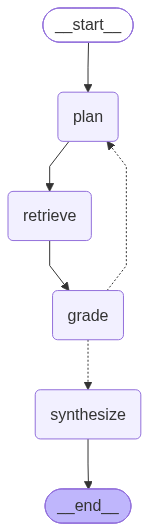

In [8]:
from IPython.display import Image, display
try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print("(no pude renderizar el PNG, muestro el mermaid)\n")
    print(app.get_graph().draw_mermaid())

## 7 · Por dónde va · ejecución con traza en vivo

Lanzamos una pregunta sobre una API concreta (los conditional edges de LangGraph) cuya respuesta NO está en el código local. Verás cómo el grafo **falla en el primer intento, vuelve al planner y escala a context7** hasta tener contexto suficiente.

In [9]:
async def correr(question):
    estado = {"question": question, "query": question, "library": "",
              "snippets": [], "sufficient": False, "reasons": "", "loops": 0, "answer": ""}
    print(f"❓ {question}\n")
    ruta = []
    final = {}
    async for paso in app.astream(estado):
        for nodo, update in paso.items():
            ruta.append(nodo)
            final.update(update)
    print("\n🧭 Ruta del grafo:  " + "  ->  ".join(ruta))
    return final

resultado = await correr("¿Cómo defino un conditional edge en LangGraph?")

❓ ¿Cómo defino un conditional edge en LangGraph?



   📝 query -> 'How to define a conditional edge in LangGraph (syntax and example)'  · librería: LangGraph


   🔎 3 fragmentos  · fuentes: ['code-local']


   ⚖️ INSUFICIENTE 🔁 · Insuficiente. Los fragmentos muestran manejo de excepciones, lectura de ficheros y un retr


   📝 query -> 'LangGraph conditional edge API example'  · librería: LangGraph


   🔎 5 fragmentos  · fuentes: ['code-local', 'context7-docs']


   ⚖️ SUFICIENTE ✅ · Sí. Los fragmentos incluyen la API concreta y un ejemplo claro: muestran StateGraph, la fu


   🧠 respuesta compuesta

🧭 Ruta del grafo:  plan  ->  retrieve  ->  grade  ->  plan  ->  retrieve  ->  grade  ->  synthesize


In [10]:
from IPython.display import Markdown, display
display(Markdown(resultado["answer"]))

Define una función que, dado el estado, devuelva la clave del siguiente nodo (o "end"/END) y luego pásala a add_conditional_edges del StateGraph. Ejemplo (del fragmento):

```python
from langgraph.graph import StateGraph
from typing import TypedDict

class AgentState(TypedDict):
    messages: list
    current_tool: str
    retry_count: int

def should_continue(state):
    if state["retry_count"] > 3:
        return "end"
    elif state["current_tool"] == "search":
        return "process_search"
    else:
        return "call_llm"

workflow = StateGraph(AgentState)
workflow.add_node("call_llm", call_llm_node)
workflow.add_node("process_search", search_node)
workflow.add_conditional_edges("call_llm", should_continue)
```

[context7-docs]

## 8 · Pruébalo tú

Cambia la pregunta. Dos casos que enseñan los otros extremos del bucle:

- **"¿Cómo capturo una excepción concreta en Python?"**: el código local SÍ lo cubre, así que el grafo va directo (`plan -> retrieve -> grade -> synthesize`), sin tocar context7.
- **"¿Cómo hago varias peticiones HTTP en paralelo con httpx?"**: context7 trae la documentación de `httpx.AsyncClient`, pero esa documentación no incluye un ejemplo de `asyncio.gather`. En nuestra ejecución el grader la juzgó insuficiente en las 3 vueltas y fue `MAX_LOOPS` quien cortó el bucle: el techo de iteraciones es parte del diseño, no un detalle.

Fíjate además en la respuesta del caso httpx: en nuestra ejecución incluía `asyncio.gather` aunque ningún fragmento lo mostraba. El synthesizer completó con su propio conocimiento pese al "usa SOLO estos fragmentos". Justo eso es lo que mide la métrica de *faithfulness* en el módulo de Evaluación de RAG.

In [11]:
resultado2 = await correr("¿Cómo capturo una excepción concreta en Python?")
display(Markdown(resultado2["answer"]))

❓ ¿Cómo capturo una excepción concreta en Python?



   📝 query -> 'How to catch a specific exception in Python'  · librería: python
   🔎 3 fragmentos  · fuentes: ['code-local']


   ⚖️ SUFICIENTE ✅ · Sí. El primer fragmento muestra la sintaxis requerida: try/except ValueError as e: print(e


   🧠 respuesta compuesta

🧭 Ruta del grafo:  plan  ->  retrieve  ->  grade  ->  synthesize


Usa except <Tipo> as <var>. Ejemplo:

try:
    riesgoso()
except ValueError as e:
    print(e)  # capturar una excepción concreta

[code-local]

In [12]:
resultado3 = await correr("¿Cómo hago varias peticiones HTTP en paralelo de forma asíncrona con httpx?")
display(Markdown(resultado3["answer"]))

❓ ¿Cómo hago varias peticiones HTTP en paralelo de forma asíncrona con httpx?



   📝 query -> 'httpx async multiple concurrent HTTP requests'  · librería: httpx


   🔎 3 fragmentos  · fuentes: ['code-local']


   ⚖️ INSUFICIENTE 🔁 · No, son insuficientes. Ningún fragmento usa la API asíncrona de httpx (p. ej. httpx.AsyncC


   📝 query -> 'httpx AsyncClient parallel asynchronous requests using asyncio.gather and asyncio.Semaphore'  · librería: httpx


...

   📝 query -> 'Parallel async HTTP requests with httpx AsyncClient using asyncio.gather, Semaphore, retries'  · librería: httpx


   🔎 5 fragmentos  · fuentes: ['code-local', 'context7-docs']


   ⚖️ INSUFICIENTE 🔁 · No, los fragmentos no bastan para responder con precisión. Lo bueno: los fragmentos de ht


   🧠 respuesta compuesta

🧭 Ruta del grafo:  plan  ->  retrieve  ->  grade  ->  plan  ->  retrieve  ->  grade  ->  plan  ->  retrieve  ->  grade  ->  synthesize


Puedes usar httpx.AsyncClient compartido entre tareas y lanzar varias tareas que hagan await a client.get(...) para ejecutar peticiones en paralelo. Un patrón típico (usando asyncio.create_task / asyncio.gather) sería:

Snippet de ejemplo:
import asyncio
import httpx

async def fetch(client, url):
    r = await client.get(url)
    return r

async def main(urls):
    async with httpx.AsyncClient() as client:
        tasks = [asyncio.create_task(fetch(client, u)) for u in urls]
        return await asyncio.gather(*tasks)

urls = ["https://example.org", "https://example.com"]
results = asyncio.run(main(urls))
for r in results:
    print(r.status_code, r.text[:100])

Explicación breve:
- httpx.AsyncClient soporta peticiones asíncronas y puede compartirse entre tareas (permite conexión pooling y HTTP/2), por lo que es adecuado para paralelizar múltiples solicitudes [context7-docs].
- Si prefieres no usar async, una alternativa es crear hilos por URL (paralelismo con threading) con el patrón threading.Thread(...).start() [code-local].
- Para reintentos automáticos en conexiones, puedes configurar el transport con retries en httpx (o implementar retries manuales) según tus necesidades [context7-docs].

Fuentes: [context7-docs] [code-local]

## Cierre

- El **RAG agéntico** convierte "recupera y responde" en un **bucle que se autocorrige**: si el
  contexto no basta, replanifica y escala a mejores fuentes.
- **LangGraph** es la herramienta natural: el ciclo es un `add_conditional_edges`, imposible de
  expresar limpio con cadenas lineales (LCEL del notebook 04).
- Una fuente **MCP (context7)** mete documentación **viva** en el retrieval: el agente deja de
  depender solo de tu índice estático.
- Y lo más útil para depurar: con `draw_mermaid_png()` ves el grafo y con `astream()` ves **la ruta
  exacta** que siguió (incluido el loop).